# Stations analysis

Analysis of `stations.csv` and `stations_status.csv`.

## Steps summary

1. Setup: loads `stations` and `station_status`.
2. Column overview of both tables.
3. Drops `rack_locks` from `stations`. Note: the column is redundant (all 2,932 values are null).
4. Counts stations with status data: 2,899 of 2,932.
5. Drops the 33 stations without status data, leaving 2,899.
6. Loads `cities` (267 rows × 7 columns) and prints its summary.
7. Drops the 82 cities without stations, leaving 185.
8. Adds local time columns to `station_status` using each city's timezone: `timezone`, `local_time`, `year`, `month`, `day`, `hour`, `minute`, `weekday`, `weekday_name`.
9. Adds `is_weekend`: 2,225,416 `False`, 700,551 `True`.
10. Lists the 185 cities, sorted by name.
11. Displays the first 30 time-ordered `station_status` rows (with `utc_time` and `gap_s`) for the 5 stations with the most rows. Note: the data seems to be polled at regular intervals (every minute) but cleaned so that only changes are kept.
12. Counts `station_status` rows by local hour, local month and country (2,925,967 rows in total). Note: "usage" is measured as the number of `station_status` rows (chosen over drops in `bikes` and trip counts).
13. Plots the Step 12 counts (hour, month, country) as bar charts.
14. Plots hourly `station_status` row counts as one bar chart per month (12) and one per country (12).
15. Reads the GHS-SMOD settlement class at each station's location into `ghs_smod` (2,899 rows): 1,119 urban centre, 1,437 urban cluster, 343 rural. Note: GHS-SMOD (R2023A, 1 km grid) chosen as the rural/urban source, linked to stations by location.
16. Adds `smod_class` and `smod_level1` to `station_status` and plots row counts by local hour and month per SMOD level 1 group (3) and per SMOD class (7). Note: the different types of area (rural/urban) do not have any major difference in usage across hours of the day and months.
17. Merges `smod_class` and `smod_level1` into `stations` (2,899 rows × 12 columns, every station has a class).
18. Plots hourly `station_status` row counts for weekdays vs weekends, for all stations and per SMOD level 1 group (weekday 2,225,416 rows over 224 dates, weekend 700,551 rows over 89 dates). Note: on weekdays there is a small increase in bike usage during the rush hour between 7-9. This is true for both rural and urban areas.

### Step 1: Setup

Imports pandas and numpy and loads `stations.csv` and `stations_status.csv` from `./data`.

In [1]:
import pandas as pd
import numpy as np

In [2]:
stations = pd.read_csv("./data/stations.csv", sep=",")
station_status = pd.read_csv("./data/stations_status.csv", sep=",")

### Step 2: Column overview: `stations` and `station_status`

Builds a table with one row per column, giving its dtype, non-null count, null count, number of unique values and the value in the first row. Prints it for `stations` and `station_status` along with the shape of each table.

In [3]:
def column_overview(df):
    return pd.DataFrame({
        "dtype": df.dtypes,
        "non_null": df.notna().sum(),
        "nulls": df.isna().sum(),
        "n_unique": df.nunique(),
        "example": df.iloc[0],
    })

for name, df in {"stations": stations, "station_status": station_status}.items():
    print(f"\n{name} - shape: {df.shape}")
    display(column_overview(df))


stations - shape: (2932, 11)


,dtype,non_null,nulls,n_unique,example
id,int64,2932,0,2932,142186362
city_id,int64,2932,0,185,135
name,str,2932,0,2855,BIKE 500100
app_number,int64,2932,0,2914,0
terminal_type,str,2345,587,10,NaN
place_type,int64,2932,0,16,12
bike_racks,int64,2932,0,33,0
special_racks,int64,2932,0,11,0
rack_locks,float64,0,2932,0,NaN
lon,float64,2932,0,2912,7.821669



station_status - shape: (2925967, 8)


,dtype,non_null,nulls,n_unique,example
station_id,int64,2925967,0,2899,101896428
time,float64,2925967,0,392858,1661530441.0
bikes,int64,2925967,0,185,2
booked_bikes,int64,2925967,0,40,0
bikes_available_to_rent,int64,2925967,0,185,2
free_racks,int64,2925967,0,68,0
free_special_racks,int64,2925967,0,38,0
maintenance,bool,2925967,0,2,False


### Step 3: Drop `rack_locks` from `stations`

All 2,932 values in `rack_locks` are null, so the column carries no information. The code checks that every value is null, drops the column and prints the new shape and column list.

In [4]:
assert stations["rack_locks"].isna().all()

stations = stations.drop(columns=["rack_locks"])
print(stations.shape)
print(list(stations.columns))

(2932, 10)
['id', 'city_id', 'name', 'app_number', 'terminal_type', 'place_type', 'bike_racks', 'special_racks', 'lon', 'lat']


### Step 4: Stations with and without `station_status` data

Compares the set of station IDs in `stations` with the set of `station_id` values in `station_status`. Prints how many stations have at least one status record, how many have none, and how many status IDs do not appear in `stations`. Shows the rows of `stations` that have no status records.

In [5]:
station_ids = set(stations["id"])
status_ids = set(station_status["station_id"])

with_status = station_ids & status_ids
without_status = station_ids - status_ids
status_not_in_stations = status_ids - station_ids

print("Stations total:", len(station_ids))
print(f"With status data: {len(with_status)} ({len(with_status) / len(station_ids):.2%})")
print("Without status data:", len(without_status))
print("Status station IDs missing from stations:", len(status_not_in_stations))

stations_without_status = stations[stations["id"].isin(without_status)]
stations_without_status

Stations total: 2932
With status data: 2899 (98.87%)
Without status data: 33
Status station IDs missing from stations: 0


,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,7.821669,51.677449
11,258292,176,Hangar 10 am Flugplatz 5618,5618,stele,6,6,0,14.146521,53.876952
13,140911390,833,TMB Test station,34980,stele,14,10,0,2.143654,41.346571
28,11268759,557,Święta Jadwiga,3787,7inch,0,15,0,18.946631,50.292195
54,115413819,64,Ma. Enzersdorf / Gabrium,1,NaN,0,0,0,16.299178,48.094352
71,405832,302,Gnien Pembroke,6866,sign,0,8,0,14.488521,35.929510
92,216612,176,Pension Delia Will Ahlbeck 5615,5615,sign,6,6,0,14.179120,53.941858
93,271479,176,Ferienpark Benz 5616,5616,stele,6,6,0,14.074235,53.939402
102,405841,302,Mater Dei Hospital,6871,sign,0,12,0,14.475673,35.901561
194,153092,775,Hotel Ostseeländer Züssow 57141,57141,NaN,7,6,0,13.553034,53.979870


### Step 5: Drop stations with no `station_status` data

Keeps only the rows of `stations` whose `id` appears in `station_status["station_id"]`, which removes the stations listed in the previous cell. Prints the number of rows before and after, and how many were dropped.

In [6]:
n_before = len(stations)
stations = stations[stations["id"].isin(station_status["station_id"])]

print("Rows before:", n_before)
print("Rows after:", len(stations))
print("Dropped:", n_before - len(stations))

Rows before: 2932
Rows after: 2899
Dropped: 33


### Step 6: Load `cities` and summarise it

Loads `cities.csv` from `./data` into `cities`. Prints the shape and `info()` (column names, dtypes, non-null counts), then shows `describe(include="all")` transposed so there is one row per column (count, unique, top and freq for text columns; mean, std, min, quartiles and max for numeric ones).

In [7]:
cities = pd.read_csv("./data/cities.csv", sep=",")

print(cities.shape)
cities.info()
cities.describe(include="all").T

(267, 7)
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 12.9 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,267.0,NaN,NaN,NaN,496.985019,232.77276,1.0,314.0,537.0,691.5,858.0
name,267,267,Zagreb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,267.0,NaN,NaN,NaN,49.067596,4.155125,27.8154,47.82785,49.898,51.58975,57.6902
lon,267.0,NaN,NaN,NaN,12.154192,7.02984,-15.5182,8.30655,13.7446,16.8312,33.4535
timezone,267,9,Europe/Berlin,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,267,15,DE,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_to_official_only,267,2,True,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 7: Drop cities with no stations

Keeps only the rows of `cities` whose `id` appears in `stations["city_id"]`. `stations` at this point already excludes stations without status data. Prints the number of rows before and after, and how many were dropped.

In [8]:
n_before = len(cities)
cities = cities[cities["id"].isin(stations["city_id"])]

print("Rows before:", n_before)
print("Rows after:", len(cities))
print("Dropped:", n_before - len(cities))

Rows before: 267
Rows after: 185
Dropped: 82


### Step 8: Local time columns for `station_status`

Looks up each status row's timezone through `station_id` → `stations.city_id` → `cities.timezone` and stores it in a `timezone` column. Converts the Unix timestamp in `time` (seconds, UTC) to the local time of that timezone, one timezone at a time, and stores it as `local_time` (without a timezone attached, since the rows use several different ones). From `local_time` it adds `year`, `month`, `day`, `hour` (0–23), `minute`, `weekday` (0 = Monday to 6 = Sunday) and `weekday_name`. Prints how many rows have no timezone and shows the first rows of the new columns.

In [9]:
# station id -> timezone of its city
station_tz = stations[["id", "city_id"]].merge(
    cities[["id", "timezone"]], left_on="city_id", right_on="id", suffixes=("", "_city")
).set_index("id")["timezone"]
station_status["timezone"] = station_status["station_id"].map(station_tz)
print("Rows without a timezone:", station_status["timezone"].isna().sum())

# Unix seconds (UTC) -> local wall-clock time, converted one timezone at a time
utc_time = pd.to_datetime(station_status["time"], unit="s", utc=True)
local_time = pd.Series(pd.NaT, index=station_status.index, dtype="datetime64[ns]")
for tz, idx in station_status.groupby("timezone").groups.items():
    local_time.loc[idx] = utc_time.loc[idx].dt.tz_convert(tz).dt.tz_localize(None)
station_status["local_time"] = local_time

station_status["year"] = station_status["local_time"].dt.year
station_status["month"] = station_status["local_time"].dt.month
station_status["day"] = station_status["local_time"].dt.day
station_status["hour"] = station_status["local_time"].dt.hour            # 0-23
station_status["minute"] = station_status["local_time"].dt.minute
station_status["weekday"] = station_status["local_time"].dt.weekday      # 0 = Monday ... 6 = Sunday
station_status["weekday_name"] = station_status["local_time"].dt.day_name()

station_status[["station_id", "time", "timezone", "local_time", "year", "month",
                "day", "hour", "minute", "weekday", "weekday_name"]].head()

Rows without a timezone: 0


,station_id,time,timezone,local_time,year,month,day,hour,minute,weekday,weekday_name
0,101896428,1.661530e+09,Europe/Berlin,2022-08-26 18:14:01,2022,8,26,18,14,4,Friday
1,54643,1.661531e+09,Europe/Berlin,2022-08-26 18:15:01,2022,8,26,18,15,4,Friday
2,6201611,1.661531e+09,Europe/Brussels,2022-08-26 18:15:01,2022,8,26,18,15,4,Friday
3,294346,1.661531e+09,Europe/Riga,2022-08-26 19:15:01,2022,8,26,19,15,4,Friday
4,781866,1.661531e+09,Europe/Riga,2022-08-26 19:15:01,2022,8,26,19,15,4,Friday


### Step 9: `is_weekend` column

Adds a boolean `is_weekend` column to `station_status`: `True` when `weekday` is 5 (Saturday) or 6 (Sunday), `False` otherwise. Prints the count of each value.

In [10]:
station_status["is_weekend"] = station_status["weekday"] >= 5

station_status["is_weekend"].value_counts()

is_weekend
False    2225416
True      700551
Name: count, dtype: int64

### Step 10: List of cities

Displays every row of `cities` (after Step 7), sorted by `name`, with the index reset. `display.max_rows` is set to `None` inside the cell so all rows are shown.

In [11]:
with pd.option_context("display.max_rows", None):
    display(cities.sort_values("name").reset_index(drop=True))

,id,name,lat,lon,timezone,country,return_to_official_only
0,414,Amstetten,48.12180,14.877400,Europe/Berlin,AT,False
1,689,Bad Oeynhausen,52.20510,8.800740,Europe/Berlin,DE,True
2,621,Baden-Baden,48.73650,8.304820,Europe/Berlin,DE,False
3,833,Barcelona,41.40950,2.171770,Europe/Berlin,ES,True
4,332,Bensheim,49.68030,8.618900,Europe/Berlin,DE,True
5,676,Bergisches e-Bike,51.01920,7.180250,Europe/Berlin,DE,True
6,131,Bottrop,51.52630,6.946110,Europe/Berlin,DE,False
7,627,Bruchsal,49.12600,8.596800,Europe/Berlin,DE,False
8,392,Bürstadt,49.64610,8.449170,Europe/Berlin,DE,True
9,776,Chełm,51.13180,23.475500,Europe/Warsaw,PL,True


### Step 11: Time data of the 5 stations with the most `station_status` rows

Finds the 5 `station_id` values with the most rows in `station_status` and prints their row counts. For each of these stations, sorts its rows by `time` and adds two columns to a copy: `utc_time` (the Unix `time` as a UTC datetime) and `gap_s` (seconds since the station's previous row). Prints the station name and row count, and displays the first `n_show` (30) rows with the time columns and the state columns (`bikes`, `booked_bikes`, `bikes_available_to_rent`, `free_racks`, `free_special_racks`, `maintenance`). `station_status` itself is not changed.

In [26]:
n_show = 10   # rows shown per station

top5_ids = station_status["station_id"].value_counts().head(5)
print(top5_ids)

time_cols = ["station_id", "time", "utc_time", "local_time", "gap_s",
             "bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks", "maintenance"]

for station_id in top5_ids.index:
    rows = station_status[station_status["station_id"] == station_id].sort_values("time").copy()
    rows["utc_time"] = pd.to_datetime(rows["time"], unit="s")
    rows["gap_s"] = rows["time"].diff()          # seconds since the station's previous row
    name = stations.loc[stations["id"] == station_id, "name"].iloc[0]
    print(f"\nStation {station_id} ({name}): {len(rows):,} rows, first {n_show} shown")
    display(rows[time_cols].head(n_show))

station_id
286234       16643
142141673    15786
54635        15541
86926732     15323
142141545    13869
Name: count, dtype: int64

Station 286234 (Bahnhof Sursee): 16,643 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
85085,286234,1.661526e+09,2022-08-26 15:06:01,2022-08-26 17:06:01,NaN,9,0,9,0,0,False
85102,286234,1.661526e+09,2022-08-26 15:07:01,2022-08-26 17:07:01,60.0,10,0,10,0,0,False
85138,286234,1.661527e+09,2022-08-26 15:09:01,2022-08-26 17:09:01,120.0,11,0,11,0,0,False
85201,286234,1.661527e+09,2022-08-26 15:13:01,2022-08-26 17:13:01,240.0,12,0,12,0,0,False
85398,286234,1.661528e+09,2022-08-26 15:25:01,2022-08-26 17:25:01,720.0,13,0,13,0,0,False
85421,286234,1.661528e+09,2022-08-26 15:26:01,2022-08-26 17:26:01,60.0,14,0,14,0,0,False
85877,286234,1.661529e+09,2022-08-26 15:50:01,2022-08-26 17:50:01,1440.0,13,0,13,0,0,False
85985,286234,1.661529e+09,2022-08-26 15:56:01,2022-08-26 17:56:01,360.0,12,0,12,0,0,False
86041,286234,1.661530e+09,2022-08-26 15:59:01,2022-08-26 17:59:01,180.0,13,0,13,0,0,False
86076,286234,1.661530e+09,2022-08-26 16:01:01,2022-08-26 18:01:01,120.0,14,0,14,0,0,False



Station 142141673 (El Parador): 15,786 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
1233924,142141673,1.675100e+09,2023-01-30 17:34:01,2023-01-30 18:34:01,NaN,0,0,0,14,0,False
1233929,142141673,1.675100e+09,2023-01-30 17:35:01,2023-01-30 18:35:01,60.0,9,0,9,13,0,False
1234332,142141673,1.675109e+09,2023-01-30 19:55:01,2023-01-30 20:55:01,8400.0,10,0,10,12,0,False
1234562,142141673,1.675116e+09,2023-01-30 22:06:01,2023-01-30 23:06:01,7860.0,9,0,9,13,0,False
1234573,142141673,1.675117e+09,2023-01-30 22:17:01,2023-01-30 23:17:01,660.0,10,0,10,12,0,False
1234599,142141673,1.675119e+09,2023-01-30 22:44:01,2023-01-30 23:44:01,1620.0,9,0,9,13,0,False
1234635,142141673,1.675123e+09,2023-01-30 23:59:01,2023-01-31 00:59:01,4500.0,8,0,8,14,0,False
1236511,142141673,1.675167e+09,2023-01-31 12:05:01,2023-01-31 13:05:01,43560.0,9,0,9,13,0,False
1236721,142141673,1.675169e+09,2023-01-31 12:49:01,2023-01-31 13:49:01,2640.0,8,0,8,14,0,False
1236905,142141673,1.675172e+09,2023-01-31 13:27:01,2023-01-31 14:27:01,2280.0,9,0,9,13,0,False



Station 54635 (Wr. Neustadt / Hauptbahnhof): 15,541 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
84864,54635,1.661526e+09,2022-08-26 14:54:01,2022-08-26 16:54:01,NaN,15,0,15,0,0,False
84898,54635,1.661526e+09,2022-08-26 14:56:01,2022-08-26 16:56:01,120.0,14,0,14,0,0,False
85155,54635,1.661527e+09,2022-08-26 15:10:01,2022-08-26 17:10:01,840.0,15,0,15,0,0,False
86211,54635,1.661530e+09,2022-08-26 16:07:01,2022-08-26 18:07:01,3420.0,17,0,17,0,0,False
773,54635,1.661533e+09,2022-08-26 16:54:01,2022-08-26 18:54:01,2820.0,15,0,15,0,0,False
793,54635,1.661533e+09,2022-08-26 16:55:01,2022-08-26 18:55:01,60.0,14,0,14,0,0,False
820,54635,1.661533e+09,2022-08-26 16:56:01,2022-08-26 18:56:01,60.0,13,0,13,0,0,False
2285,54635,1.661538e+09,2022-08-26 18:15:01,2022-08-26 20:15:01,4740.0,14,0,14,0,0,False
2553,54635,1.661539e+09,2022-08-26 18:29:01,2022-08-26 20:29:01,840.0,15,0,15,0,0,False
2658,54635,1.661539e+09,2022-08-26 18:36:01,2022-08-26 20:36:01,420.0,17,0,17,0,0,False



Station 86926732 (Tržnica Veruda): 15,323 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
4258,86926732,1.661547e+09,2022-08-26 20:51:01,2022-08-26 22:51:01,NaN,2,0,2,2,2,False
14400,86926732,1.661617e+09,2022-08-27 16:17:01,2022-08-27 18:17:01,69960.0,4,0,4,2,2,False
16139,86926732,1.661622e+09,2022-08-27 17:43:01,2022-08-27 19:43:01,5160.0,2,0,2,2,2,False
16834,86926732,1.661624e+09,2022-08-27 18:18:01,2022-08-27 20:18:01,2100.0,0,0,0,2,2,False
21599,86926732,1.661661e+09,2022-08-28 04:22:01,2022-08-28 06:22:01,36240.0,1,0,1,1,1,False
32038,86926732,1.661708e+09,2022-08-28 17:26:01,2022-08-28 19:26:01,47040.0,2,0,2,1,1,False
32054,86926732,1.661708e+09,2022-08-28 17:27:01,2022-08-28 19:27:01,60.0,3,0,3,1,1,False
32106,86926732,1.661708e+09,2022-08-28 17:29:01,2022-08-28 19:29:01,120.0,1,0,1,1,1,False
32364,86926732,1.661709e+09,2022-08-28 17:44:01,2022-08-28 19:44:01,900.0,1,0,1,2,2,False
32634,86926732,1.661710e+09,2022-08-28 18:04:01,2022-08-28 20:04:01,1200.0,0,0,0,2,2,False



Station 142141545 (TRAM Walden): 13,869 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
1233784,142141545,1.675098e+09,2023-01-30 17:06:01,2023-01-30 18:06:01,NaN,9,0,9,13,0,False
1236088,142141545,1.675160e+09,2023-01-31 10:16:01,2023-01-31 11:16:01,61800.0,10,0,10,12,0,False
1236495,142141545,1.675166e+09,2023-01-31 12:01:01,2023-01-31 13:01:01,6300.0,9,0,9,13,0,False
1236498,142141545,1.675167e+09,2023-01-31 12:02:01,2023-01-31 13:02:01,60.0,8,0,8,14,0,False
1236502,142141545,1.675167e+09,2023-01-31 12:03:01,2023-01-31 13:03:01,60.0,9,0,9,13,0,False
1237004,142141545,1.675173e+09,2023-01-31 13:51:01,2023-01-31 14:51:01,6480.0,8,0,8,14,0,False
1237057,142141545,1.675174e+09,2023-01-31 14:04:01,2023-01-31 15:04:01,780.0,9,0,9,13,0,False
1237482,142141545,1.675179e+09,2023-01-31 15:23:01,2023-01-31 16:23:01,4740.0,10,0,10,12,0,False
1238647,142141545,1.675196e+09,2023-01-31 20:08:01,2023-01-31 21:08:01,17100.0,9,0,9,13,0,False
1238679,142141545,1.675196e+09,2023-01-31 20:17:01,2023-01-31 21:17:01,540.0,10,0,10,12,0,False


### Step 12: `station_status` record counts by hour, month and country

Counts the rows of `station_status` in each group:
1. by local `hour` (from Step 8),
2. by local `month` (from Step 8),
3. by country, found by linking `station_id` → `stations.city_id` → `cities.country`. Sorted from most to fewest rows.

In [12]:
by_hour = station_status.groupby("hour").size().rename("records")
by_hour

hour
0      47642
1      35141
2      26526
3      22448
4      25389
5      41708
6      74399
7     134172
8     137891
9     124279
10    120963
11    138523
12    158849
13    178702
14    194190
15    209154
16    227343
17    225143
18    205148
19    175649
20    146310
21    117611
22     91946
23     66841
Name: records, dtype: int64

In [13]:
by_month = station_status.groupby("month").size().rename("records")
by_month

month
1     110438
2     138982
3     213703
4     308125
5     280834
6     491598
7     253738
8      85997
9     369992
10    363426
11    206644
12    102490
Name: records, dtype: int64

In [14]:
# station id -> country of its city
station_country = stations[["id", "city_id"]].merge(
    cities[["id", "country"]], left_on="city_id", right_on="id", suffixes=("", "_city")
).set_index("id")["country"]

by_country = station_status["station_id"].map(station_country).value_counts().rename("records")
by_country

station_id
PL    908603
DE    743405
ES    297611
GB    192759
AT    167921
HR    167720
CZ    164818
CH    148663
SI    101366
CY     17318
LV     13952
MT      1831
Name: records, dtype: int64

### Step 13: Bar charts of the Step 12 counts

Plots `by_hour`, `by_month` and `by_country` from Step 12 as three bar charts stacked in one matplotlib figure. The y-axis shows the number of `station_status` rows, in thousands.

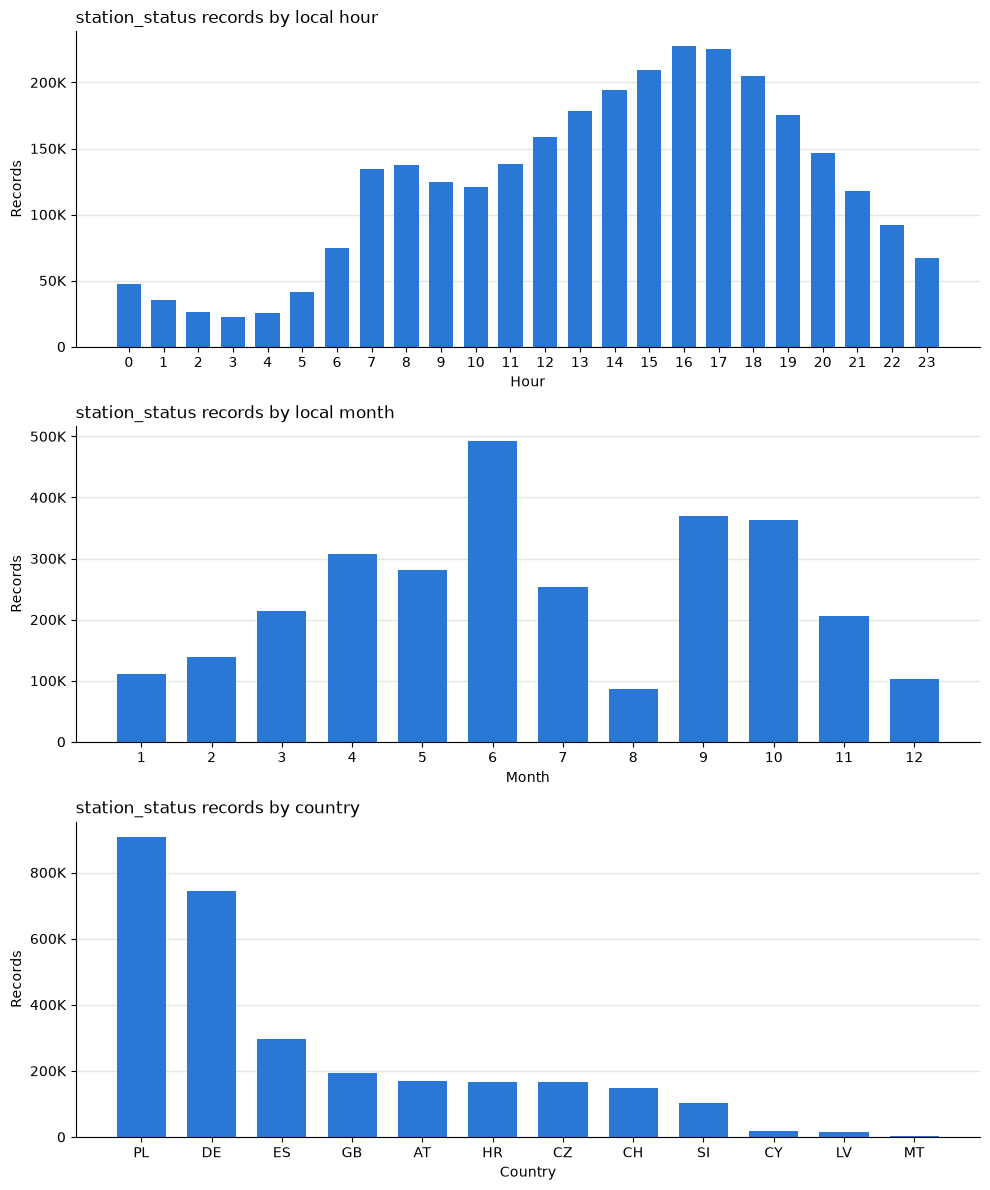

In [15]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

bar_color = "#2a78d6"
thousands = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}K" if v else "0")

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
charts = [
    (by_hour, "station_status records by local hour", "Hour"),
    (by_month, "station_status records by local month", "Month"),
    (by_country, "station_status records by country", "Country"),
]
for ax, (series, title, xlabel) in zip(axes, charts):
    ax.bar(series.index.astype(str), series.values, color=bar_color, width=0.7, zorder=2)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Records")
    ax.yaxis.set_major_formatter(thousands)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

### Step 14: Hourly `station_status` record counts per month and per country

Two figures of bar charts, one small chart per group, each counting `station_status` rows by local `hour` (0–23):
1. **Per month:** a 3 × 4 grid with one chart per local `month`. All charts share the same y-axis scale.
2. **Per country:** a 3 × 4 grid with one chart per country (country found through `station_id` → `stations.city_id` → `cities.country`), ordered from most to fewest rows. Each chart has its own y-axis scale, and its title shows the country's total number of rows in brackets.

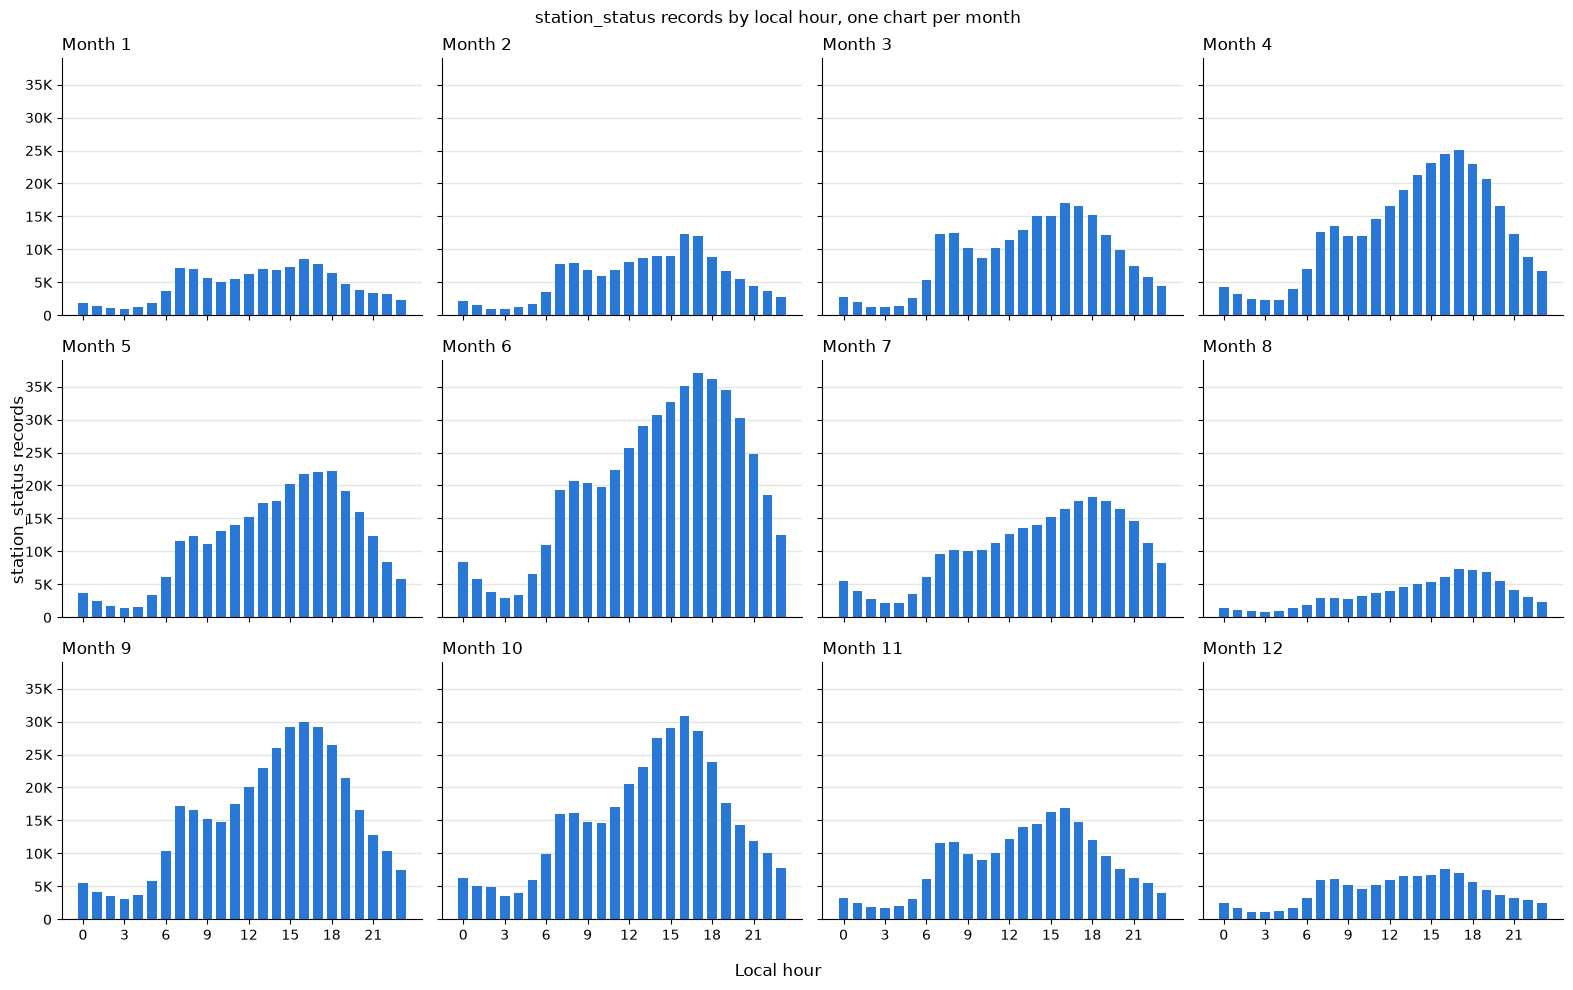

In [16]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

bar_color = "#2a78d6"
compact = FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:,.0f}")

# rows: month, columns: local hour 0-23, values: number of station_status rows
hour_by_month = (
    station_status.groupby(["month", "hour"]).size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey=True)
for ax, (month, counts) in zip(axes.flat, hour_by_month.iterrows()):
    ax.bar(counts.index, counts.values, color=bar_color, width=0.7, zorder=2)
    ax.set_title(f"Month {month}", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.yaxis.set_major_formatter(compact)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

fig.supxlabel("Local hour")
fig.supylabel("station_status records")
fig.suptitle("station_status records by local hour, one chart per month")
fig.tight_layout()
plt.show()

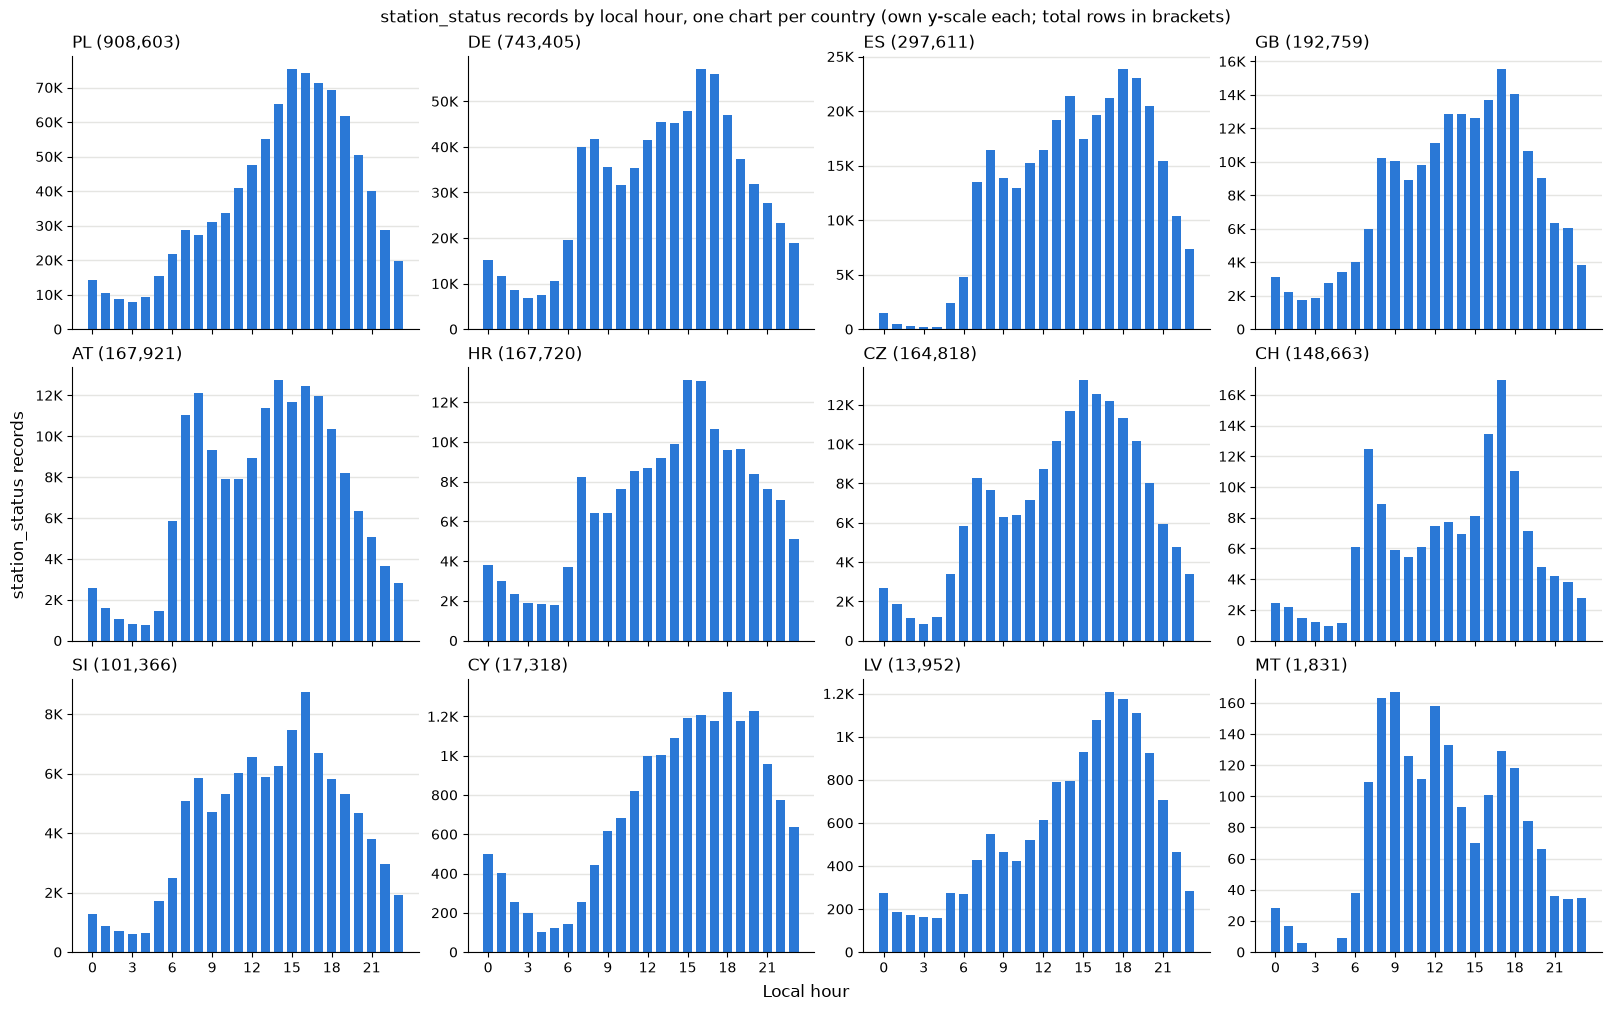

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

bar_color = "#2a78d6"
compact = FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:,.0f}")

# station id -> country of its city
station_country = stations[["id", "city_id"]].merge(
    cities[["id", "country"]], left_on="city_id", right_on="id", suffixes=("", "_city")
).set_index("id")["country"]

# rows: country, columns: local hour 0-23, values: number of station_status rows
hour_by_country = (
    station_status.groupby([station_status["station_id"].map(station_country).rename("country"), "hour"]).size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)
# countries ordered from most to fewest rows
hour_by_country = hour_by_country.loc[hour_by_country.sum(axis=1).sort_values(ascending=False).index]

fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, layout="constrained")
for ax, (country, counts) in zip(axes.flat, hour_by_country.iterrows()):
    ax.bar(counts.index, counts.values, color=bar_color, width=0.7, zorder=2)
    ax.set_title(f"{country} ({counts.sum():,})", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.yaxis.set_major_formatter(compact)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

fig.supxlabel("Local hour")
fig.supylabel("station_status records")
fig.suptitle("station_status records by local hour, one chart per country (own y-scale each; total rows in brackets)")
plt.show()

### Step 15: GHS-SMOD settlement class for each station

Opens the GHS-SMOD raster (`GHS_SMOD_E2030_GLOBE_R2023A_54009_1000_V2_0.tif`, 1 km grid, World Mollweide projection) with `rasterio`. Converts each station's `lon`/`lat` to the raster's coordinates with `pyproj` and reads the value of the grid cell under the station. Builds a `ghs_smod` DataFrame with one row per station:
- `station_id`, `x`, `y` (grid coordinates in metres)
- `smod_code`: the raster value (the no-data value -200 becomes `<NA>`)
- `smod_class`: the level 2 class name for the code
- `smod_level1`: the level 1 group (Urban centre / Urban cluster / Rural, plus Water)

Class codes are from the GHSL Data Package 2023. Prints the shape and the counts of `smod_level1` and `smod_class`. Requires `rasterio` and `pyproj`.

In [18]:
import rasterio
from pyproj import Transformer

ghs_path = "./data/GHS_SMOD_E2030_GLOBE_R2023A_54009_1000_V2_0/GHS_SMOD_E2030_GLOBE_R2023A_54009_1000_V2_0.tif"

# GHS-SMOD level 2 class codes and their level 1 group
# Source: GHSL_Data_Package_2023.pdf (in the downloaded GHS-SMOD folder)
#   p. 56: level 1 classes (3 Urban Centre, 2 Urban Cluster, 1 Rural)
#   pp. 56-57: level 2 classes 30, 23, 22, 21, 13, 12, 11 and 10 (Water)
smod_class = {
    30: "Urban centre",
    23: "Dense urban cluster",
    22: "Semi-dense urban cluster",
    21: "Suburban or peri-urban",
    13: "Rural cluster",
    12: "Low density rural",
    11: "Very low density rural",
    10: "Water",
}
smod_level1 = {30: "Urban centre", 23: "Urban cluster", 22: "Urban cluster", 21: "Urban cluster",
               13: "Rural", 12: "Rural", 11: "Rural", 10: "Water"}

with rasterio.open(ghs_path) as src:
    # station lon/lat (WGS84) -> grid coordinates (World Mollweide, metres)
    to_grid = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
    x, y = to_grid.transform(stations["lon"].to_numpy(), stations["lat"].to_numpy())
    # value of the grid cell under each station
    codes = np.array([value[0] for value in src.sample(zip(x, y))])
    nodata = src.nodata

ghs_smod = pd.DataFrame({"station_id": stations["id"].to_numpy(), "x": x, "y": y, "smod_code": codes})
ghs_smod["smod_code"] = ghs_smod["smod_code"].astype("Int64")
ghs_smod.loc[ghs_smod["smod_code"] == nodata, "smod_code"] = pd.NA
ghs_smod["smod_class"] = ghs_smod["smod_code"].map(smod_class)
ghs_smod["smod_level1"] = ghs_smod["smod_code"].map(smod_level1)

print(ghs_smod.shape)
print(ghs_smod["smod_level1"].value_counts(dropna=False))
print(ghs_smod["smod_class"].value_counts(dropna=False))
ghs_smod.head()

(2899, 6)
smod_level1
Urban cluster    1437
Urban centre     1119
Rural             343
Name: count, dtype: int64
smod_class
Urban centre                1119
Dense urban cluster          784
Suburban or peri-urban       515
Low density rural            174
Semi-dense urban cluster     138
Rural cluster                125
Very low density rural        44
Name: count, dtype: int64


,station_id,x,y,smod_code,smod_class,smod_level1
0,940986,9.955353e+05,6.294868e+06,12,Low density rural,Rural
1,93646685,9.993904e+05,6.293101e+06,13,Rural cluster,Rural
2,111365509,-2.735846e+05,6.498408e+06,23,Dense urban cluster,Urban cluster
3,405835,1.273478e+06,4.326949e+06,30,Urban centre,Urban centre
4,8612883,1.280130e+06,4.321890e+06,30,Urban centre,Urban centre


### Step 16: Hourly and monthly `station_status` record counts per GHS-SMOD group

Adds `smod_class` and `smod_level1` columns to `station_status` by mapping `station_id` to `ghs_smod` (Step 15), and prints how many rows have no class. Defines `plot_counts_per_group`, which counts `station_status` rows per group and per time value and draws one bar chart per group. Each chart has its own y-axis scale and its title shows the group's total rows in brackets. Groups are ordered from most to least urban.

Four figures:
1. by local `hour`, one chart per `smod_level1` group
2. by local `month`, one chart per `smod_level1` group
3. by local `hour`, one chart per `smod_class`
4. by local `month`, one chart per `smod_class`

The counts behind each figure are kept in `hour_by_level1`, `month_by_level1`, `hour_by_class` and `month_by_class`.

In [19]:
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# settlement class of each status row, through station_id -> ghs_smod (Step 15)
station_smod = ghs_smod.set_index("station_id")
station_status["smod_class"] = station_status["station_id"].map(station_smod["smod_class"])
station_status["smod_level1"] = station_status["station_id"].map(station_smod["smod_level1"])
print("Rows without a class:", station_status["smod_class"].isna().sum())

# group order: most to least urban
smod_class_order = ["Urban centre", "Dense urban cluster", "Semi-dense urban cluster", "Suburban or peri-urban",
                    "Rural cluster", "Low density rural", "Very low density rural"]
smod_level1_order = ["Urban centre", "Urban cluster", "Rural"]

bar_color = "#2a78d6"
compact = FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:,.0f}")


def plot_counts_per_group(group_col, group_order, time_col, time_values, xticks, n_cols, title):
    """One bar chart per group: number of station_status rows for each value of time_col.
    Each chart has its own y-axis scale; the title shows the group's total rows."""
    counts = (
        station_status.groupby([group_col, time_col]).size()
        .unstack(fill_value=0)
        .reindex(index=[g for g in group_order if g in station_status[group_col].unique()],
                 columns=time_values, fill_value=0)
    )
    n_rows = math.ceil(len(counts) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows),
                             sharex=True, squeeze=False, layout="constrained")
    for ax, (group, row) in zip(axes.flat, counts.iterrows()):
        ax.bar(row.index, row.values, color=bar_color, width=0.7, zorder=2)
        ax.set_title(f"{group} ({row.sum():,})", loc="left")
        ax.set_xticks(xticks)
        ax.tick_params(labelbottom=True)
        ax.yaxis.set_major_formatter(compact)
        ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in axes.flat[len(counts):]:
        ax.set_visible(False)
    fig.supxlabel(f"Local {time_col}")
    fig.supylabel("station_status records")
    fig.suptitle(title + " (own y-scale each; total rows in brackets)")
    plt.show()
    return counts

Rows without a class: 0


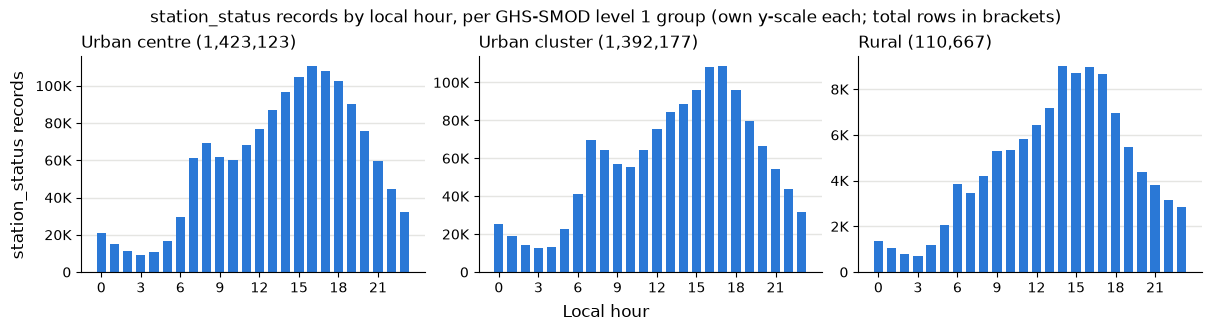

In [20]:
hour_by_level1 = plot_counts_per_group("smod_level1", smod_level1_order, "hour", range(24), range(0, 24, 3), 3,
                                       "station_status records by local hour, per GHS-SMOD level 1 group")

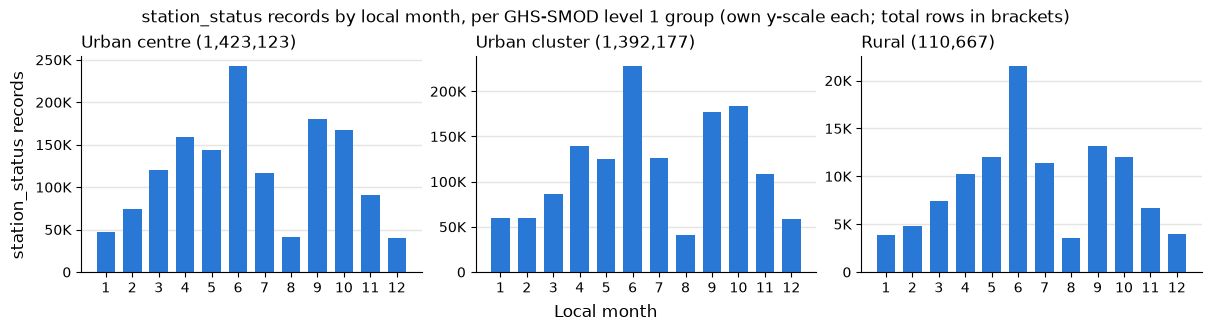

In [21]:
month_by_level1 = plot_counts_per_group("smod_level1", smod_level1_order, "month", range(1, 13), range(1, 13), 3,
                                        "station_status records by local month, per GHS-SMOD level 1 group")

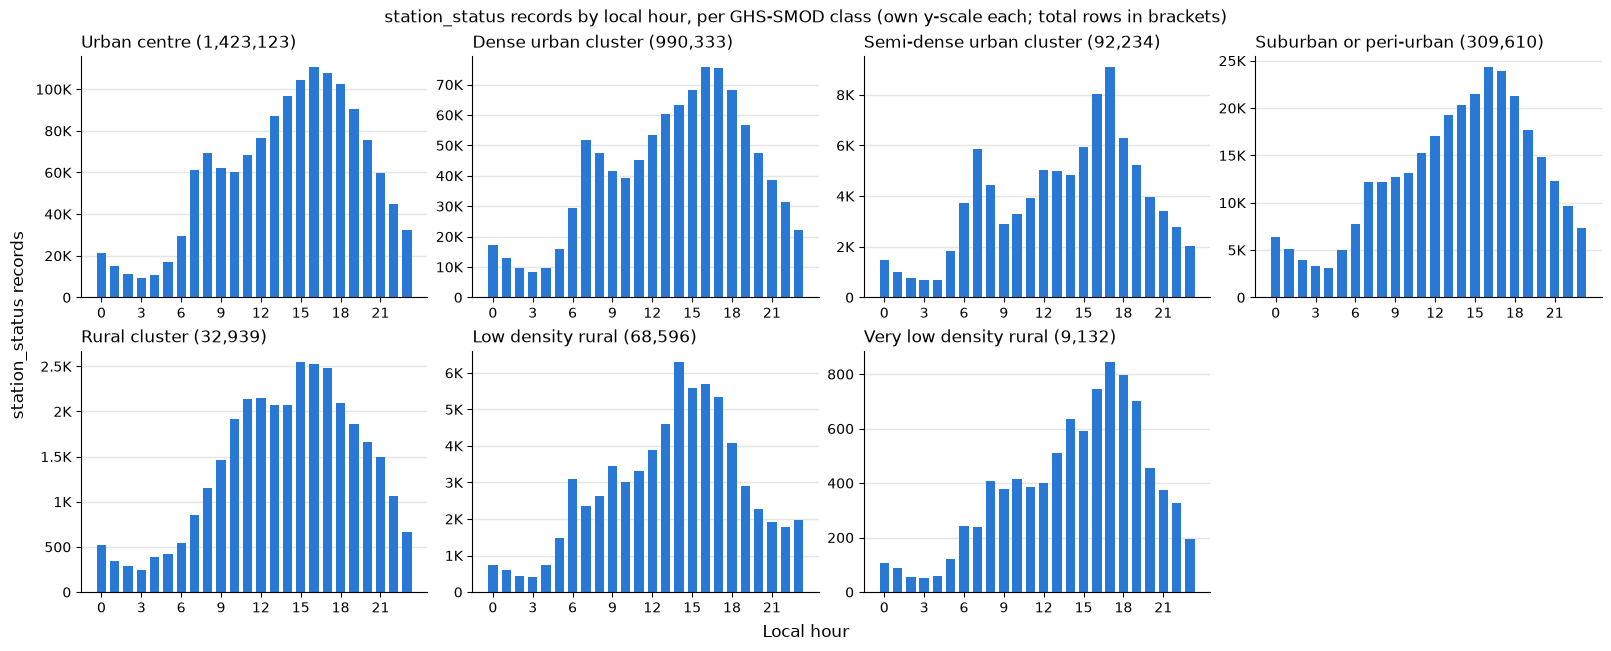

In [22]:
hour_by_class = plot_counts_per_group("smod_class", smod_class_order, "hour", range(24), range(0, 24, 3), 4,
                                      "station_status records by local hour, per GHS-SMOD class")

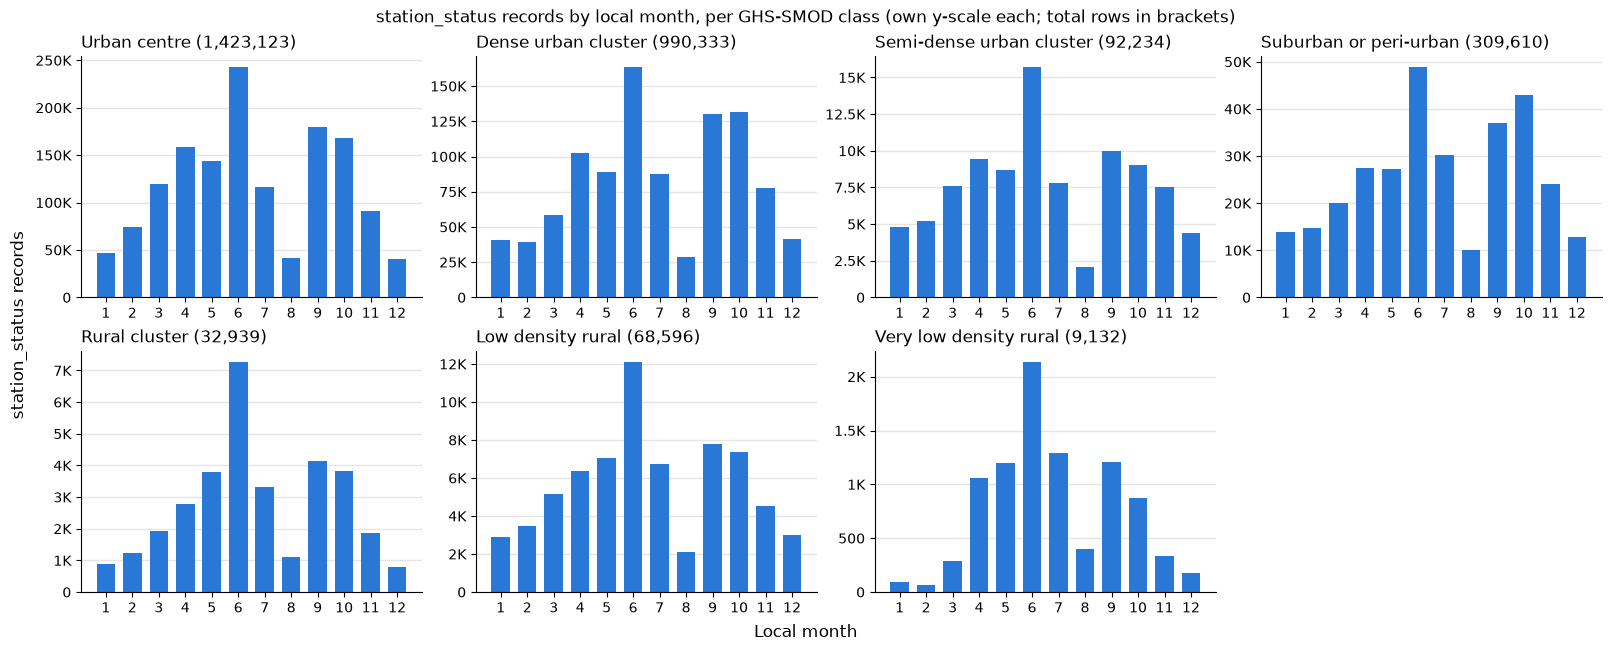

In [23]:
month_by_class = plot_counts_per_group("smod_class", smod_class_order, "month", range(1, 13), range(1, 13), 4,
                                       "station_status records by local month, per GHS-SMOD class")

### Step 17: Merge the GHS-SMOD classes into `stations`

Left-merges `smod_class` and `smod_level1` from `ghs_smod` (Step 15) into `stations`, matching `stations.id` to `ghs_smod.station_id` (checked as one-to-one). Drops the extra `station_id` column after the merge. Prints the row counts before and after, the number of stations without a class, and the new shape. The merge gives `stations` a new 0-based index.

In [24]:
n_before = len(stations)
stations = stations.merge(
    ghs_smod[["station_id", "smod_class", "smod_level1"]],
    left_on="id", right_on="station_id", how="left", validate="one_to_one",
).drop(columns=["station_id"])

print("Rows before:", n_before, "| after:", len(stations))
print("Stations without a class:", stations["smod_class"].isna().sum())
print(stations.shape)
stations.head()

Rows before: 2899 | after: 2899
Stations without a class: 0
(2899, 12)


,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,lon,lat,smod_class,smod_level1
0,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,13.868973,54.090538,Low density rural,Rural
1,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,13.918970,54.073088,Rural cluster,Rural
2,111365509,243,Station Road,8494,smart_sign,0,20,0,-3.936120,56.119272,Dense urban cluster,Urban cluster
3,405835,302,Birkirkara Road,6868,sign,0,6,0,14.481456,35.906836,Urban centre,Urban centre
4,8612883,302,Wasteserv,6839,7inch,0,6,0,14.552025,35.862522,Urban centre,Urban centre


### Step 18: Hourly `station_status` record counts, weekday vs weekend

Labels each `station_status` row as "Weekday" or "Weekend" from `is_weekend` (Step 9), without adding a column to the table, and defines `draw_hour_bars`, which draws one bar chart of row counts for hours 0–23. Two figures, each chart with its own y-axis scale and the total rows in its title:
1. **All stations:** one chart for weekdays and one for weekends (`hour_by_day_type`).
2. **Per GHS-SMOD level 1 group:** a 3 × 2 grid, one row per `smod_level1` group (Urban centre, Urban cluster, Rural; from Step 16) and one column per day type (`hour_by_level1_day_type`).

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

bar_color = "#2a78d6"
compact = FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:,.0f}")
day_type_order = ["Weekday", "Weekend"]
smod_level1_order = ["Urban centre", "Urban cluster", "Rural"]

# "Weekday" / "Weekend" label for each status row, from is_weekend (Step 9)
day_type = station_status["is_weekend"].map({False: "Weekday", True: "Weekend"}).rename("day_type")


def draw_hour_bars(ax, counts, title):
    """Bar chart of row counts for hours 0-23 on one axis."""
    ax.bar(counts.index, counts.values, color=bar_color, width=0.7, zorder=2)
    ax.set_title(f"{title} ({counts.sum():,})", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.tick_params(labelbottom=True)
    ax.yaxis.set_major_formatter(compact)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

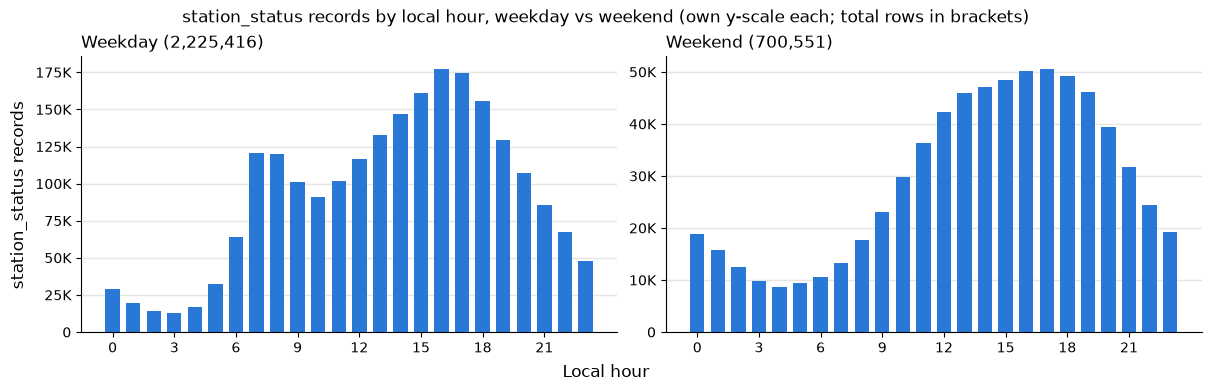

In [30]:
# rows: Weekday / Weekend, columns: local hour 0-23, values: number of station_status rows
hour_by_day_type = (
    station_status.groupby([day_type, "hour"]).size()
    .unstack(fill_value=0)
    .reindex(index=day_type_order, columns=range(24), fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, (dt, counts) in zip(axes, hour_by_day_type.iterrows()):
    draw_hour_bars(ax, counts, dt)
fig.supxlabel("Local hour")
fig.supylabel("station_status records")
fig.suptitle("station_status records by local hour, weekday vs weekend (own y-scale each; total rows in brackets)")
plt.show()

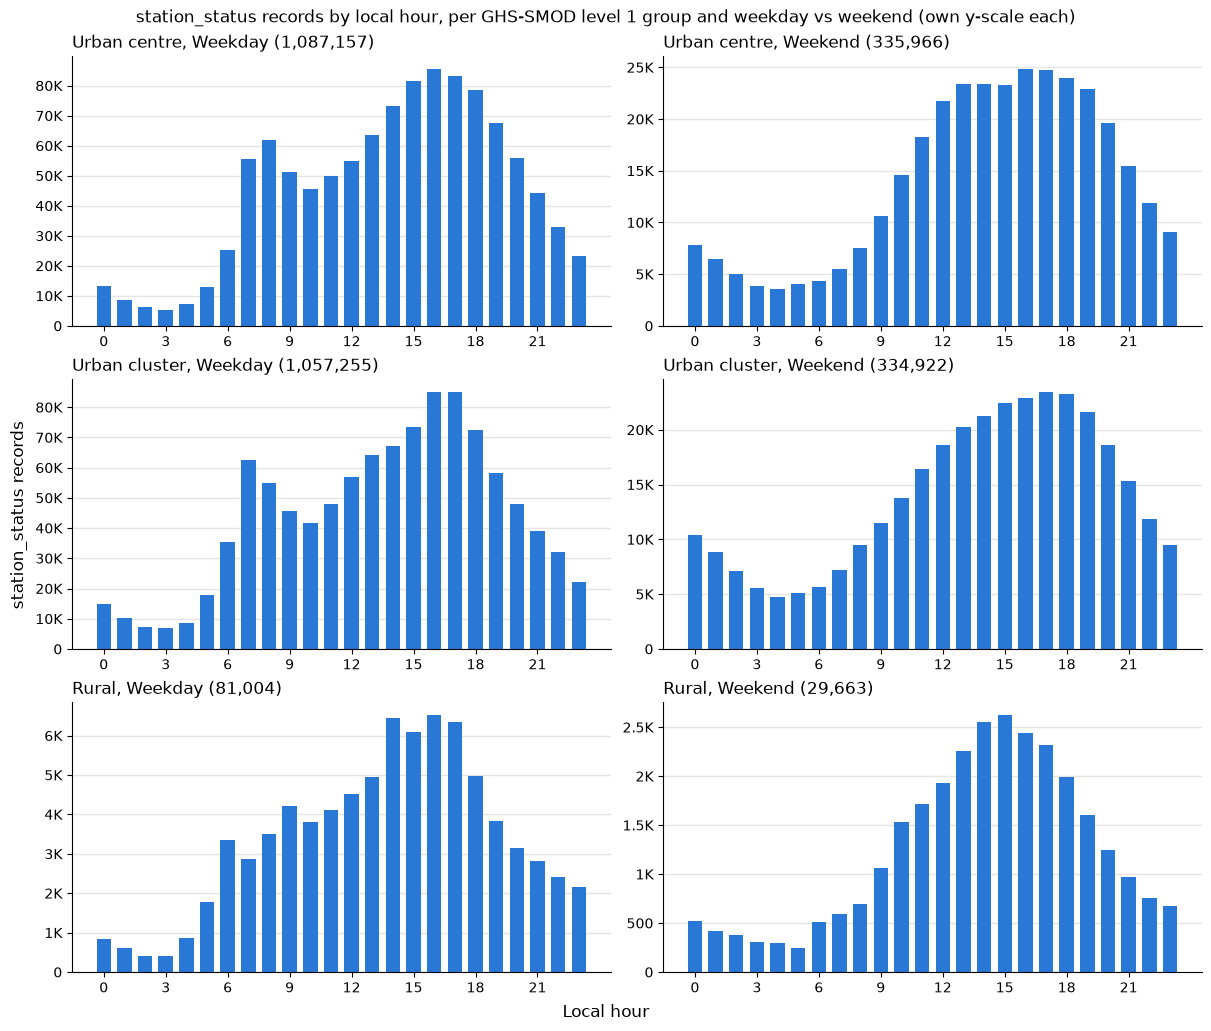

In [31]:
# rows: (smod_level1, day type), columns: local hour 0-23, values: number of station_status rows
hour_by_level1_day_type = (
    station_status.groupby(["smod_level1", day_type, "hour"]).size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

fig, axes = plt.subplots(len(smod_level1_order), 2, figsize=(12, 3.4 * len(smod_level1_order)), layout="constrained")
for r, level in enumerate(smod_level1_order):
    for c, dt in enumerate(day_type_order):
        draw_hour_bars(axes[r, c], hour_by_level1_day_type.loc[(level, dt)], f"{level}, {dt}")
fig.supxlabel("Local hour")
fig.supylabel("station_status records")
fig.suptitle("station_status records by local hour, per GHS-SMOD level 1 group and weekday vs weekend (own y-scale each)")
plt.show()